# Recommender systems: collaborative filtering and content-based ranking

A recommender suggests items to a user. This notebook builds three on the same data and compares them:

1. **Collaborative filtering** with [Surprise](https://surpriselib.com/)'s `SVD`, a matrix factorization that predicts the rating a user would give a movie.
2. **Content-based ranking**, which describes each movie by its genres and matches them to the user's taste.
3. **PureSVD**, a matrix factorization built to pick a top 10 rather than to predict ratings.

A popularity ranking (the most-rated movies first) is the baseline every method has to beat.
An LLM used as a ranker, after Netflix's GenRec, is in `week5-llm-ranker.ipynb`.

**Data:** [MovieLens 100K](https://grouplens.org/datasets/movielens/100k/) from GroupLens at the University of Minnesota:
100,000 ratings (1 to 5) from 943 users on 1,682 movies, collected in 1997 and 1998.
Its licence allows research and teaching use, asks you to cite F. Maxwell Harper and Joseph A. Konstan,
"The MovieLens Datasets: History and Context", ACM TiiS 5(4), 2015, and does not allow redistribution or commercial use.
So this notebook downloads it (5 MB) instead of shipping a copy.

**Setup:** `pip install scikit-surprise` (version 1.1.5 or later runs on NumPy 2). It runs in under a minute on a laptop CPU.

In [1]:
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.sparse import csr_matrix
from scipy.sparse.linalg import svds
from surprise import SVD, BaselineOnly, Dataset, accuracy
from surprise.model_selection import train_test_split

## 1. Load MovieLens 100K

Surprise downloads the data the first time (`prompt=False` skips its "download?" question) and keeps it in `~/.surprise_data/`.
The ratings come as (user, movie, rating) triples. The movie titles and genres are in the file `u.item` next to them.

In [2]:
data = Dataset.load_builtin("ml-100k", prompt=False)
folder = os.path.expanduser("~/.surprise_data/ml-100k/ml-100k/")

genres = pd.read_csv(folder + "u.genre", sep="|", header=None)[0].tolist()
movies = pd.read_csv(folder + "u.item", sep="|", encoding="latin-1", header=None,
                     names=["id", "title", "date", "video", "url"] + genres)
movies["id"] = movies["id"].astype(str)  # Surprise keeps ids as strings
movies = movies.set_index("id")

ratings = pd.DataFrame(data.raw_ratings, columns=["user", "movie", "rating", "timestamp"])
print(f"{len(ratings):,} ratings, {ratings.user.nunique()} users, {ratings.movie.nunique():,} movies")
print("Genres:", ", ".join(genres))
ratings.head().assign(title=lambda d: movies.loc[d.movie, "title"].to_numpy())

Trying to download dataset from https://files.grouplens.org/datasets/movielens/ml-100k.zip...


Done! Dataset ml-100k has been saved to /work/.surprise_data/ml-100k
100,000 ratings, 943 users, 1,682 movies
Genres: unknown, Action, Adventure, Animation, Children's, Comedy, Crime, Documentary, Drama, Fantasy, Film-Noir, Horror, Musical, Mystery, Romance, Sci-Fi, Thriller, War, Western


,user,movie,rating,timestamp,title
0,196,242,3.0,881250949,Kolya (1996)
1,186,302,3.0,891717742,L.A. Confidential (1997)
2,22,377,1.0,878887116,Heavyweights (1994)
3,244,51,2.0,880606923,Legends of the Fall (1994)
4,166,346,1.0,886397596,Jackie Brown (1997)


## 2. Collaborative filtering: predict a rating

Collaborative filtering uses only who rated what. It needs no description of the movies.

Matrix factorization gives every user a short vector of numbers, and every movie one of the same length.
The predicted rating is the overall average, plus a user bias (some people rate everything high),
plus a movie bias (some movies are liked by everyone), plus the dot product of the two vectors:

$$\hat r_{ui} = \mu + b_u + b_i + p_u \cdot q_i$$

The vectors are learned by stochastic gradient descent on the known ratings only.
Surprise calls this `SVD`, after Simon Funk's Netflix Prize method, though it is not the linear-algebra SVD.

`BaselineOnly` keeps only the average and the two biases. It shows how much the vectors add.

In [3]:
trainset, testset = train_test_split(data, test_size=0.2, random_state=0)

baseline = BaselineOnly(verbose=False).fit(trainset)
algo = SVD(n_factors=100, random_state=0).fit(trainset)

print(f"RMSE, biases only: {accuracy.rmse(baseline.test(testset), verbose=False):.3f}")
print(f"RMSE, SVD:         {accuracy.rmse(algo.test(testset), verbose=False):.3f}")

RMSE, biases only: 0.955
RMSE, SVD:         0.946


Both are off by just under one star on average. The vectors help a little.

One prediction: how would user 196 rate movie 302?

In [4]:
prediction = algo.predict(uid="196", iid="302")
print(prediction)
print("Movie 302 is", movies.loc["302", "title"])

user: 196        item: 302        r_ui = None   est = 4.41   {'was_impossible': False}
Movie 302 is L.A. Confidential (1997)


## 3. A top 10 for one user

To recommend, score every movie the user has not rated yet, and sort.
The factors give all the scores at once: one matrix product instead of 1,600 calls to `predict`.

In [5]:
item_ids = np.array([trainset.to_raw_iid(i) for i in range(trainset.n_items)])  # column -> movie id
n_ratings = np.array([len(trainset.ir[i]) for i in range(trainset.n_items)])  # how many people rated each

svd_scores = trainset.global_mean + algo.bu[:, None] + algo.bi[None, :] + algo.pu @ algo.qi.T


def seen_by(u):
    "Columns of the movies user u (an inner id) rated in the training set."
    return np.array([i for i, _ in trainset.ur[u]])


def top10(scores, u):
    s = scores.astype(float).copy()
    s[seen_by(u)] = -np.inf  # never recommend what they already rated
    best = np.argsort(-s)[:10]
    return pd.DataFrame({"title": movies.loc[item_ids[best], "title"].to_numpy(),
                         "score": s[best].round(2), "rated by": n_ratings[best]})


user = trainset.to_inner_uid("196")
top10(svd_scores[user], user)

,title,score,rated by
0,Schindler's List (1993),4.52,233
1,"Shawshank Redemption, The (1994)",4.45,231
2,L.A. Confidential (1997),4.41,236
3,Citizen Kane (1941),4.41,151
4,"Close Shave, A (1995)",4.41,87
5,"Third Man, The (1949)",4.38,61
6,"Treasure of the Sierra Madre, The (1948)",4.34,61
7,Casablanca (1942),4.29,186
8,To Kill a Mockingbird (1962),4.29,176
9,North by Northwest (1959),4.29,144


Most of these are famous, highly rated classics.
A movie that everyone rates highly gets a big movie bias, so it lands near the top of almost everyone's list.
That is a good guess at the stars. Section 5 tests whether it is a good guess at what the user will like next.

## 4. Content-based ranking

Content-based ranking describes each movie by its features: here, the 19 genre flags in `u.item`.
A user's profile adds up the genres of the movies they rated, weighted by how far each rating is above or below their own average.
Each unseen movie is then scored by its cosine similarity to that profile.

In [6]:
G = movies.loc[item_ids, genres].to_numpy(float)  # one row of 0/1 genre flags per movie
G /= np.maximum(np.linalg.norm(G, axis=1, keepdims=True), 1e-9)  # unit length, for cosine similarity


def profile(u):
    "The user's taste: the genres of the movies they rated, weighted by rating minus their own average."
    r = np.array([rating for _, rating in trainset.ur[u]])
    return ((r - r.mean())[:, None] * G[seen_by(u)]).sum(axis=0)


def content_scores(u):
    return G @ profile(u)


print("User 196's taste by genre (above 0: likes):")
print((pd.Series(profile(user), index=genres).round(1) + 0.0).sort_values().to_string())  # + 0.0 turns -0.0 into 0.0
top10(content_scores(user), user)

User 196's taste by genre (above 0: likes):
Action        -2.9
Adventure     -2.1
Sci-Fi        -0.6
War           -0.5
Children's    -0.4
Comedy        -0.2
Crime          0.0
Animation      0.0
Mystery        0.0
Horror         0.0
Musical        0.0
Film-Noir      0.0
Romance        0.0
Western        0.0
Thriller       0.0
unknown        0.0
Fantasy        0.2
Documentary    0.4
Drama          2.8


,title,score,rated by
0,Last Dance (1996),2.85,8
1,Entertaining Angels: The Dorothy Day Story (1996),2.85,1
2,"Death in the Garden (Mort en ce jardin, La) (1...",2.85,1
3,Quiz Show (1994),2.85,132
4,Three Wishes (1995),2.85,8
5,Moll Flanders (1996),2.85,36
6,Three Colors: White (1994),2.85,46
7,To Live (Huozhe) (1994),2.85,10
8,Broken English (1996),2.85,6
9,"Star Maker, The (Uomo delle stelle, L') (1995)",2.85,11


User 196 likes dramas, so every movie tagged only "Drama" gets the same top score.
With nothing but genres to go on, the ranker cannot tell one drama from another.

Content-based ranking has one thing collaborative filtering lacks: it can score a movie nobody has rated yet (the **cold start** problem).
Matrix factorization has no vector for a new movie, so every new movie gets the same score for a given user.

In [7]:
print("SVD, a new movie:      ", round(algo.predict("196", "new-movie-1").est, 2))
print("SVD, another new movie:", round(algo.predict("196", "new-movie-2").est, 2))

new_drama = np.array([g == "Drama" for g in genres], float)
new_action = np.array([g in ("Action", "Adventure") for g in genres], float)
for name, v in (("a new drama", new_drama), ("a new action film", new_action)):
    print(f"Content, {name}: {v @ profile(user) / np.linalg.norm(v):.2f}")

SVD, a new movie:       3.44
SVD, another new movie: 3.44
Content, a new drama: 2.85
Content, a new action film: -3.50


## 5. Which ranker finds the movies people liked?

A fair test for a recommender asks: of the 10 movies it shows a user, how many did the user go on to like?
For each user, the movies they rated 4 or 5 in the test set are the hits.
Each method ranks every movie the user has not rated in the training set, and we count the hits in its top 10 (**precision at 10**).

The fourth method is **PureSVD** (Cremonesi, Koren and Turrin, [RecSys 2010](https://doi.org/10.1145/1864708.1864721)).
It fills every missing rating with 0 and takes a truncated SVD of the whole user-by-movie matrix: the same SVD as in the dimensionality-reduction lecture.
The zeros carry information: they say which movies a user chose *not* to watch.

925 users
Popularity          0.135
Content (genres)    0.017
SVD (ratings)       0.078
PureSVD             0.266
Name: precision at 10, dtype: float64


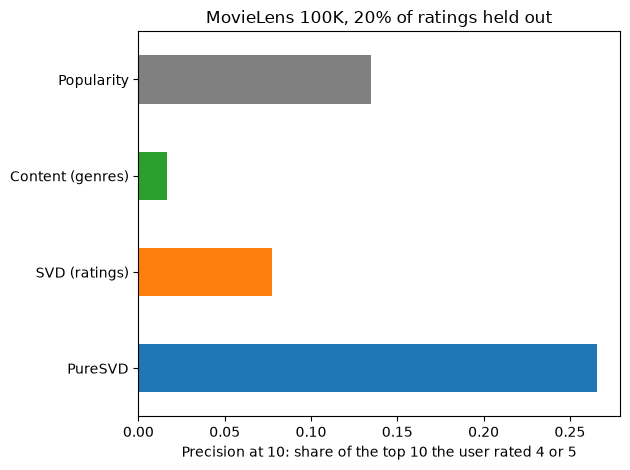

In [8]:
users, cols, values = zip(*trainset.all_ratings())
R = csr_matrix((np.array(values), (users, cols)), shape=(trainset.n_users, trainset.n_items))
U, S, Vt = svds(R, k=20)  # keep 20 factors
puresvd_scores = (U * S) @ Vt

test = pd.DataFrame(testset, columns=["user", "movie", "rating"])
liked = test[test.rating >= 4].groupby("user").movie.apply(set)

rankers = {
    "Popularity": lambda u: n_ratings,
    "Content (genres)": content_scores,
    "SVD (ratings)": lambda u: svd_scores[u],
    "PureSVD": lambda u: puresvd_scores[u],
}
precision = {name: [] for name in rankers}
for raw_user, hits in liked.items():
    u = trainset.to_inner_uid(raw_user)
    for name, scores in rankers.items():
        s = np.asarray(scores(u), float).copy()
        s[seen_by(u)] = -np.inf
        top = set(item_ids[np.argsort(-s)[:10]])
        precision[name].append(len(top & hits) / 10)

results = pd.Series({name: np.mean(p) for name, p in precision.items()}, name="precision at 10")
print(f"{len(liked)} users")
print(results.round(3))

ax = results.plot.barh(color=["grey", "tab:green", "tab:orange", "tab:blue"])
ax.invert_yaxis()
ax.set_xlabel("Precision at 10: share of the top 10 the user rated 4 or 5")
ax.set_title("MovieLens 100K, 20% of ratings held out")
plt.tight_layout()
plt.show()

## What this shows

- **Surprise's SVD predicts ratings well and picks a poor top 10.** It loses to plain popularity, because it was trained to guess the stars, not the choice.
- **PureSVD roughly doubles popularity.** It is also a matrix factorization, but it learns from *which* movies people rated, so it ranks what they are likely to watch.
- **Genres alone are a thin description**, so content-based ranking scores lowest here. It earns its place for new movies with no ratings, which is why real systems are hybrids.
- **Always run the popularity baseline.** It is cheap and hard to beat, and a method that loses to it is not ready.
- **Retraining:** both SVDs retrain on the whole matrix when ratings change. Wide-and-deep models train in batches, so they can keep learning from new data.

Try: change `k=20` for PureSVD (10, 50, 100), or count only movies rated by at least 50 people, and see who wins.